In [1]:
import matplotlib.pyplot as plt
from pathlib import Path
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, sum, count, when

In [2]:
spark = SparkSession.builder \
    .appName("Goodreads_Interactions") \
    .config("spark.driver.memory", "8g") \
    .getOrCreate()

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/16 02:23:59 WARN Utils: Your hostname, LAPTOP-9SL7BIS8, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/10/16 02:23:59 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/16 02:24:01 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [3]:
DIR = Path.cwd().parent / 'data'

df_interactions = spark.read.csv(str(DIR / 'goodreads_interactions.csv'), header=True, inferSchema=True)

In [4]:
duplicates = df_interactions.groupBy('user_id', 'book_id').count().select('user_id', 'book_id', (col('count') - 1).alias('duplicate_count'))
duplicates.show()

+-------+-------+---------------+
|user_id|book_id|duplicate_count|
+-------+-------+---------------+
|      0|    915|              0|
|      0|    716|              0|
|      0|    632|              0|
|      0|    190|              0|
|      5|   7026|              0|
|      5|   7010|              0|
|      5|   6674|              0|
|      5|   6655|              0|
|      5|   6630|              0|
|      5|   6539|              0|
|      5|   6523|              0|
|      5|   5896|              0|
|      5|   5866|              0|
|      5|   5642|              0|
|      5|   5637|              0|
|      5|   5504|              0|
|      5|   4895|              0|
|      5|   4779|              0|
|      5|   4542|              0|
|      5|   4492|              0|
+-------+-------+---------------+
only showing top 20 rows


In [5]:
stats = df_interactions.select(
    count("*").alias("# shelve"),
    sum("is_read").alias("# read"),
    sum(when(col("rating") > 0, 1).otherwise(0)).alias("# rate"),
    sum("is_reviewed").alias("# review")
)
stats.show()

+---------+---------+---------+--------+
| # shelve|   # read|   # rate|# review|
+---------+---------+---------+--------+
|228648342|112131203|104551549|16219149|
+---------+---------+---------+--------+



In [6]:
rating_dist = df_interactions.groupBy('rating').count().orderBy('count', ascending=False)
rating_dist.show()

+------+---------+
|rating|    count|
+------+---------+
|     0|124096793|
|     4| 37497451|
|     5| 35506166|
|     3| 23307457|
|     2|  6189946|
|     1|  2050529|
+------+---------+



In [7]:
def get_distribution(df, entity_col, filter_condition=None):
    if filter_condition is not None:
        df_filtered = df.filter(filter_condition)
    else:
        df_filtered = df
        
    interaction_count = df_filtered.groupBy(entity_col).count().withColumnRenamed('count', 'num_interactions')
    distribution = interaction_count.groupBy('num_interactions').count().orderBy('num_interactions')
    
    return distribution.toPandas()

pdf_shelve_user = get_distribution(df_interactions, 'user_id')
pdf_read_user = get_distribution(df_interactions, 'user_id', col('is_read') > 0)
pdf_rate_user = get_distribution(df_interactions, 'user_id', col('rating') > 0)
pdf_review_user = get_distribution(df_interactions, 'user_id', col('is_reviewed') > 0)

pdf_shelve_book = get_distribution(df_interactions, 'book_id')
pdf_read_book = get_distribution(df_interactions, 'book_id', col('is_read') > 0)
pdf_rate_book = get_distribution(df_interactions, 'book_id', col('rating') > 0)
pdf_review_book = get_distribution(df_interactions, 'book_id', col('is_reviewed') > 0)

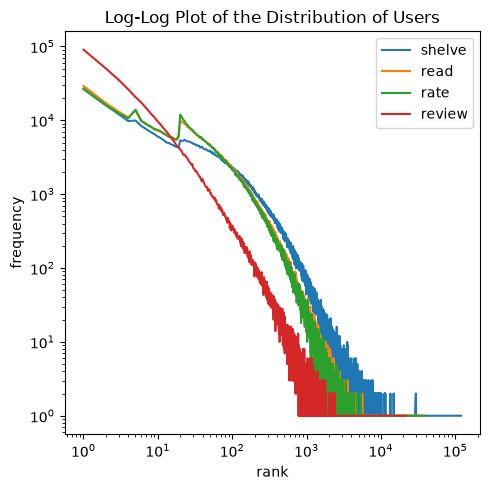

In [8]:
plt.figure(figsize=(5, 5))
plt.loglog(pdf_shelve_user['num_interactions'], pdf_shelve_user['count'], label='shelve')
plt.loglog(pdf_read_user['num_interactions'], pdf_read_user['count'], label='read')
plt.loglog(pdf_rate_user['num_interactions'], pdf_rate_user['count'], label='rate')
plt.loglog(pdf_review_user['num_interactions'], pdf_review_user['count'], label='review')
plt.xlabel('rank')
plt.ylabel('frequency')
plt.title('Log-Log Plot of the Distribution of Users')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

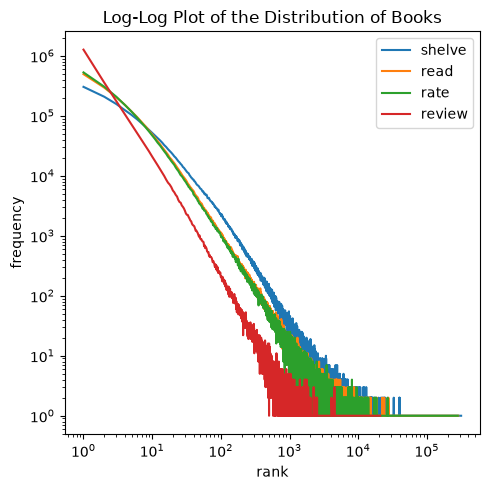

In [9]:
plt.figure(figsize=(5, 5))
plt.loglog(pdf_shelve_book['num_interactions'], pdf_shelve_book['count'], label='shelve')
plt.loglog(pdf_read_book['num_interactions'], pdf_read_book['count'], label='read')
plt.loglog(pdf_rate_book['num_interactions'], pdf_rate_book['count'], label='rate')
plt.loglog(pdf_review_book['num_interactions'], pdf_review_book['count'], label='review')
plt.xlabel('rank')
plt.ylabel('frequency')
plt.title('Log-Log Plot of the Distribution of Books')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()